# Generating class imbalance

**Imbalance** is a *row-removing* deficit: instead of (or in addition
to) changing values, the generator **drops rows** — so `Xt` is
*smaller* than `X`. Real datasets are rarely balanced: rare events,
censored observations, or biased sampling processes skew the row
distribution. This makes pipelines that assume balanced classes or
uniform feature coverage fail in instructive ways.

This notebook shows the **two levers** available in badgers:

1. **Acting on the observation process** — resample rows directly,
   with the affected rows decided by a **selector**
   (`RandomSamplingClassesGenerator` for exact per-class drops,
   `RandomSamplingTargetsGenerator` as the single score-driven
   resampler). These generators *do not use a
   DGP*.
2. **Acting on the data-generating process (DGP)** — truncate the data
   to a quantile range of a *fitted causal model*'s node
   (`CausalImbalanceGenerator`).


## Goal

Remove rows so that some classes (or score regions) become under-represented — a row-removing deficit applied with selectors.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from numpy.random import default_rng
from sklearn.datasets import make_blobs

from badgers.generators.tabular_data.imbalance.imbalance import (
    RandomSamplingTargetsGenerator, RandomSamplingClassesGenerator,
)
from badgers.core.selectors import ClassSelector, ProportionalSelector

rng = default_rng(seed=0)


In [2]:
X, y = make_blobs(centers=4, random_state=0)
# classes as a column of X
X = np.column_stack([X, y])  # NOTE: overwrites X with the 3-column version (blobs + class column)
column_mapping = {f"f{i}": i for i in range(X.shape[1])}
column_mapping["cls"] = X.shape[1] - 1
cls = X[:, column_mapping["cls"]].astype(int)   # explicit class vector for plotting
print(X.shape)

(100, 3)


## Part A — Acting on the observation process (no DGP)

### Sample data from different classes

**What the selector does here:** `ClassSelector([0, 1],
class_column=2, ...)` reads the class labels from position 2 and builds
one boolean mask per class value from the given shares. The shares are
*fractions of the total row count*, clipped to the rows available in
each class; classes absent from `proportions` are kept as-is.
`RandomSamplingClassesGenerator` then drops exactly the affected rows.

In [3]:
# WHO loses rows and how many: per-class share of the total row count
selector = ClassSelector([0, 1], class_column=2,
                         proportions={0:0.1, 1:0.05, 2:0.15, 3:0.2}, rng=rng)
gen = RandomSamplingClassesGenerator(random_generator=rng)
Xt = gen.generate(X=X.copy(), selector=selector)
print('row-removing:', X.shape, '->', Xt.shape)

row-removing: (100, 3) -> (50, 3)


In [4]:
# verify: per-class counts before and after
before = np.unique(X[:, column_mapping['cls']], return_counts=True)
after = np.unique(Xt[:, column_mapping['cls']], return_counts=True)
print('before:', dict(zip(before[0].astype(int), before[1].tolist())))
print('after :', dict(zip(after[0].astype(int), after[1].tolist())))
assert Xt.shape[0] < X.shape[0]


before: {np.int64(0): 25, np.int64(1): 25, np.int64(2): 25, np.int64(3): 25}
after : {np.int64(0): 15, np.int64(1): 20, np.int64(2): 10, np.int64(3): 5}


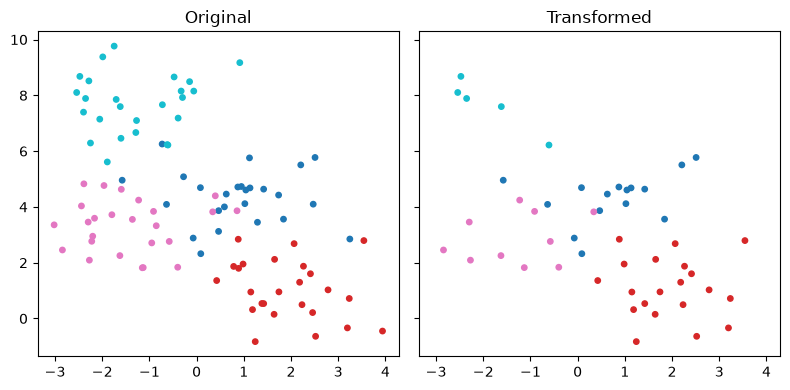

In [5]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))
axes[0].scatter(X[:, 0], X[:, 1], c=cls, cmap='tab10', s=15)
axes[1].scatter(Xt[:, 0], Xt[:, 1], c=Xt[:, column_mapping['cls']].astype(int), cmap='tab10', s=15)
axes[0].set_title('Original')
axes[1].set_title('Transformed')
plt.tight_layout()

### Sample data proportionally to a column (weighted resampling)

**What the selector does here:** `ProportionalSelector([0, 1],
column=0)` reads column 0 (`f0`) and returns per-row **float scores in
[0, 1]** — the deficit probability
grows with the value of `f0`. The consumer,
`RandomSamplingTargetsGenerator`, resamples rows with probability
proportional to `1 - score`: rows with a HIGH deficit probability are
largely dropped, rows with a LOW deficit probability are kept (and can
even be replicated). The result concentrates on small-`f0` rows — a
form of imbalance driven by a continuous column.

For illustration we also compute a demo ranking variable `score` and
use it as a color: it is **not** a target and plays no role in the
selection.

In [6]:
# demo ranking variable for coloring only
score = -2 * X[:, 0] + 3 * X[:, 1] + 5

# WHO loses rows: deficit probability proportional to f0
selector = ProportionalSelector([0, 1], column=0)
gen = RandomSamplingTargetsGenerator(random_generator=rng)
Xt = gen.generate(X=X.copy(), selector=selector)
print('row-removing:', X.shape, '->', Xt.shape)

row-removing: (100, 3) -> (100, 3)


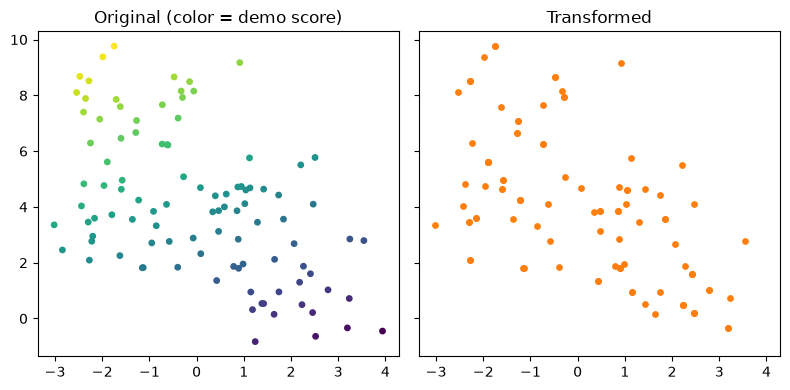

In [7]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))
axes[0].scatter(X[:, 0], X[:, 1], c=score, cmap='viridis', s=15)
axes[1].scatter(Xt[:, 0], Xt[:, 1], color='C1', s=15)
axes[0].set_title('Original (color = demo score)')
axes[1].set_title('Transformed')
plt.tight_layout()

### The removed twin: one resampler, two flavors

The former `RandomSamplingFeaturesGenerator` (a free
`sampling_proba_func` from `X` to per-row keep weights) is gone.
The score-driven resampler above covers both flavors: a fractional
selector gives the value-weighted resample (the section above), and
a boolean selector realizes an exact subsample of the never-selected
rows — the per-class drop from the first demo. Here is the same
generator, driven by the boolean masks:

In [8]:
# the same generator with a boolean selector: exact subsample
selector = ClassSelector([0, 1], class_column=2,
                         proportions={0:0.5, 1:0.25}, rng=rng)
gen = RandomSamplingTargetsGenerator(random_generator=rng)
Xt_feat = gen.generate(X.copy(), selector=selector)
print('row-removing:', X.shape, '->', Xt_feat.shape)

row-removing: (100, 3) -> (50, 3)


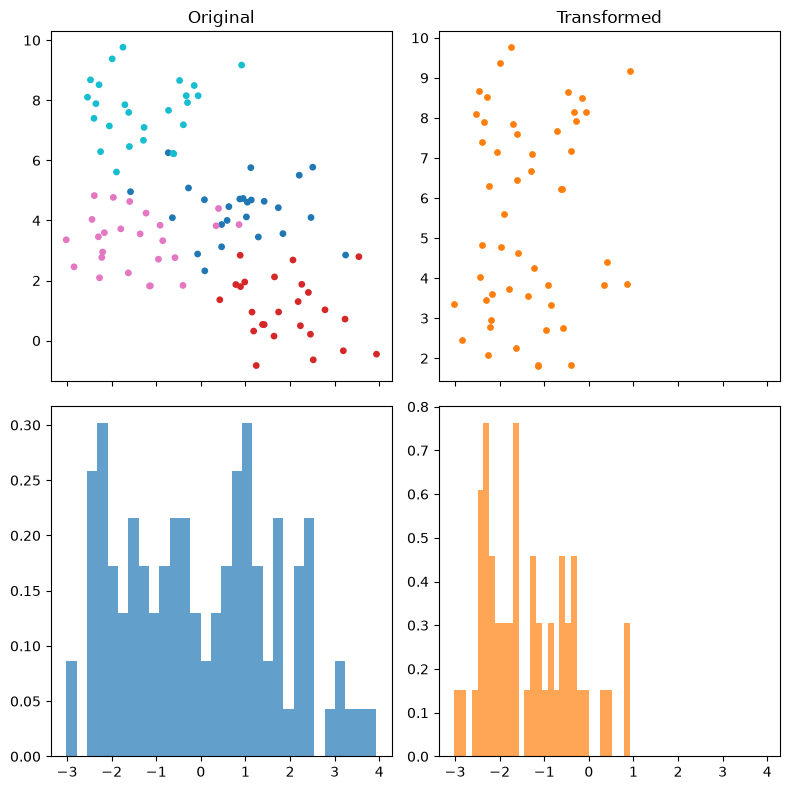

In [9]:
fig, axes = plt.subplots(2, 2, sharex=True, sharey=False, figsize=(8,8))

axes[0,0].scatter(X[:, 0], X[:, 1], c=cls, cmap='tab10', s=15)
axes[0,1].scatter(Xt_feat[:, 0], Xt_feat[:, 1], color='C1', s=15)
axes[1,0].hist(X[:, 0], bins=30, density=True, color='C0', alpha=0.7)
axes[1,1].hist(Xt_feat[:, 0], bins=30, density=True, color='C1', alpha=0.7)
axes[0,0].set_title('Original')
axes[0,1].set_title('Transformed')

plt.tight_layout()

In [10]:
from badgers.generators.tabular_data.imbalance.causal import CausalImbalanceGenerator
import dowhy.gcm as gcm
from badgers.core.dgp.backends import GcmSCMDGP


def make_scm(graph):
    scm = gcm.StructuralCausalModel(graph)
    for node in graph.nodes:
        if not list(graph.predecessors(node)):
            scm.set_causal_mechanism(node, gcm.EmpiricalDistribution())
        else:
            scm.set_causal_mechanism(node, gcm.AdditiveNoiseModel(
                prediction_model=gcm.ml.create_linear_regressor()))
    return scm


C:\Users\siebert\PycharmProjects\badgers\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Part B — Acting on the data-generating process (DGP)

`CausalImbalanceGenerator` **truncates the dataset**: it keeps only
the rows whose perturbation node falls inside `quantile_range`.
Since the kept rows are untouched (no structural equation is
re-evaluated), the descendants are untouched too — the result is a
*pure subset*: a dataset that is *imbalanced* — concentrated in one
part of the perturbation node's range — while remaining structurally
consistent by construction.


`CausalImbalanceGenerator` accepts either the built-in
`quantile_range` truncation rule, or an explicit **selector** — the
same `Selector` objects as Part A decide which rows are dropped
(row-removing polarity: an affected row is removed). With an explicit
selector, `perturbation_nodes`/`quantile_range` are ignored.


### Build the graph, generate data, fit the DGP


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

import dowhy.gcm as gcm
from badgers.core.dgp.backends import GcmSCMDGP

In [12]:
from _shared import generate_linear_data, draw_graph, plot_2panel  # from docs/tutorials/tabular-data/_shared.py

In [13]:
import networkx as nx
import pandas as pd

import dowhy.gcm as gcm
from badgers.core.dgp.backends import GcmSCMDGP

def generate_linear_data(graph, n_samples=100, rng=None, coefficients=None):
    """Generate data from a linear structural equation model."""
    nodes = list(nx.topological_sort(graph))
    if coefficients is None:
        coefficients = {}
        for node in nodes:
            parents = list(graph.predecessors(node))
            coefficients[node] = {p: rng.uniform(0.5, 2.0) * rng.choice([-1, 1]) for p in parents}
    column_mapping = {node: i for i, node in enumerate(nodes)}
    data = np.zeros((n_samples, len(nodes)))
    for node in nodes:
        i = column_mapping[node]
        parents = list(graph.predecessors(node))
        if not parents:
            data[:, i] = rng.normal(size=n_samples)
        else:
            for p, coef in coefficients[node].items():
                data[:, i] += coef * data[:, column_mapping[p]]
            data[:, i] += rng.normal(scale=0.1, size=n_samples)
    return data, column_mapping


In [14]:
# --- Build the chain X -> Y -> Z ---
chain = nx.DiGraph()
chain.add_edges_from([("X", "Y"), ("Y", "Z")])

# Part B: a fresh RNG stream (independent of Part A)
rng = np.random.default_rng(42)

X, column_mapping = generate_linear_data(
    chain, n_samples=100, rng=rng,
    coefficients={'Y': {'X': 2.0}, 'Z': {'Y': 1.0}},
)
print(f"X shape: {X.shape}")
print(f"column_mapping: {column_mapping}")

X shape: (100, 3)
column_mapping: {'X': 0, 'Y': 1, 'Z': 2}


array([[<Axes: xlabel='X', ylabel='X'>, <Axes: xlabel='Y', ylabel='X'>,
        <Axes: xlabel='Z', ylabel='X'>],
       [<Axes: xlabel='X', ylabel='Y'>, <Axes: xlabel='Y', ylabel='Y'>,
        <Axes: xlabel='Z', ylabel='Y'>],
       [<Axes: xlabel='X', ylabel='Z'>, <Axes: xlabel='Y', ylabel='Z'>,
        <Axes: xlabel='Z', ylabel='Z'>]], dtype=object)

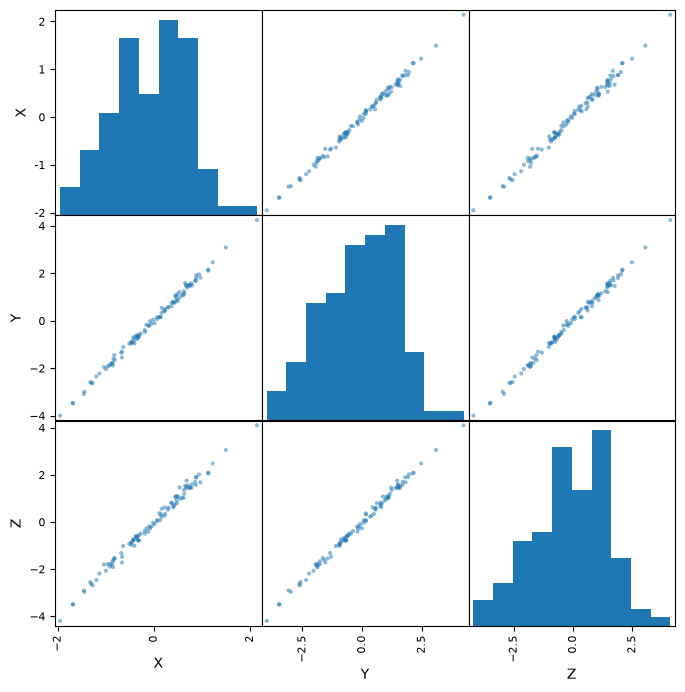

In [15]:
pd.plotting.scatter_matrix(pd.DataFrame(X, columns=column_mapping.keys()), figsize=(8, 8), diagonal='hist')

In [16]:
dgp = GcmSCMDGP(make_scm(chain), column_mapping).fit(X.copy())

gen = CausalImbalanceGenerator(random_generator=np.random.default_rng(0), dgp=dgp)
print('fitted:', dgp.is_fitted_ if hasattr(dgp, 'is_fitted_') else 'ok')

Fitting causal models:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node X:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node Y:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node Z:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node Z: 100%|██████████| 3/3 [00:00<00:00, 542.23it/s]

fitted: ok


### Generate imbalance by truncation

`quantile_range=(0.5, 1.0)` keeps the *upper* half of the Y range:
rows with Y in the lower half are dropped.

In [17]:
Xt = gen.generate(
    X.copy(),
    perturbation_nodes=["Y"],
    quantile_range=(0.5, 1.0),
)
print(f"output shape: {X.shape} -> {Xt.shape}")

output shape: (100, 3) -> (50, 3)


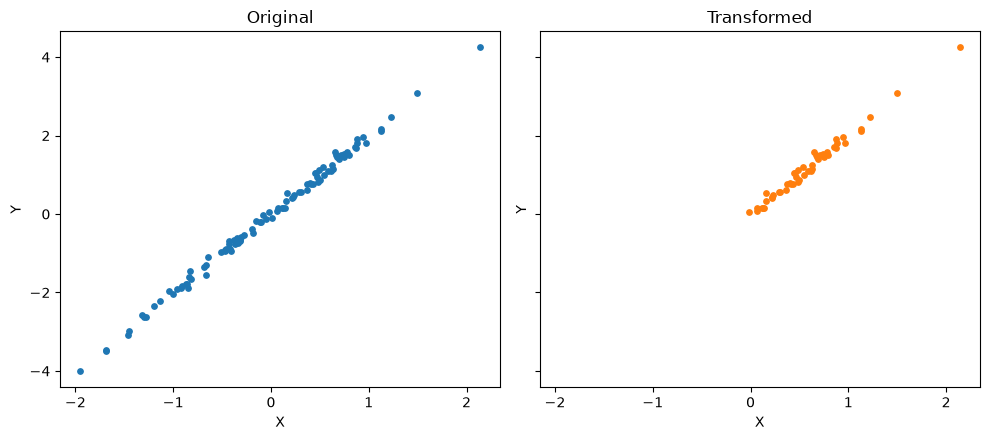

In [18]:
_ = plot_2panel(X, Xt, x_name='X', y_name='Y')

### The other half of the range

`quantile_range=(0.0, 0.5)` keeps the *lower* half of Y — the complementary imbalance:


kept 50 of 100 rows


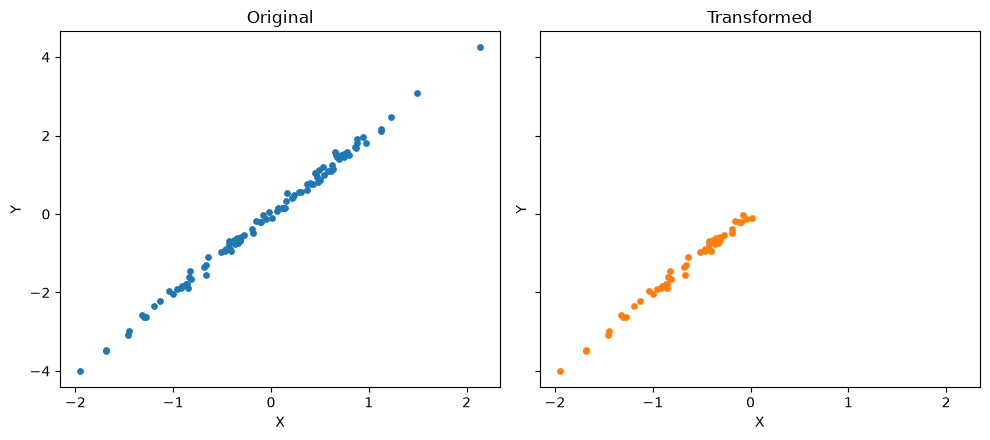

In [19]:
Xt_lo = gen.generate(
    X.copy(),
    perturbation_nodes=["Y"],
    quantile_range=(0.0, 0.5),
)
print(f"kept {Xt_lo.shape[0]} of {X.shape[0]} rows")
_ = plot_2panel(X, Xt_lo, x_name='X', y_name='Y')


The truncation removes part of the Y range; the surviving Z values are untouched (rows are kept or dropped as-is) — the Y → Z cloud is simply thinner: the same relationship, on fewer rows.

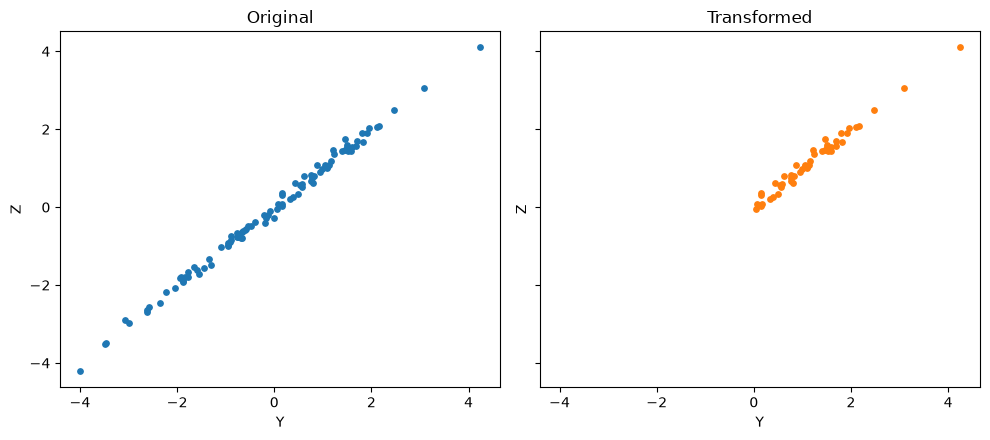

In [20]:
_ = plot_2panel(X, Xt, x_idx=1, y_idx=2, x_name='Y', y_name='Z')

### Generate imbalance with an explicit selector

The same selection machinery as Part A also plugs into the causal
generator: an affected row is dropped. Here a `TopQuantileSelector`
keeps rows where X is *low* (it affects the rows where X is high):

In [21]:
from badgers.core.selectors import TopQuantileSelector

sel = TopQuantileSelector([0], column=0, quantile=0.8)

Xt = gen.generate(X.copy(), selector=sel)
print(f"output shape: {X.shape} -> {Xt.shape}")

output shape: (100, 3) -> (80, 3)


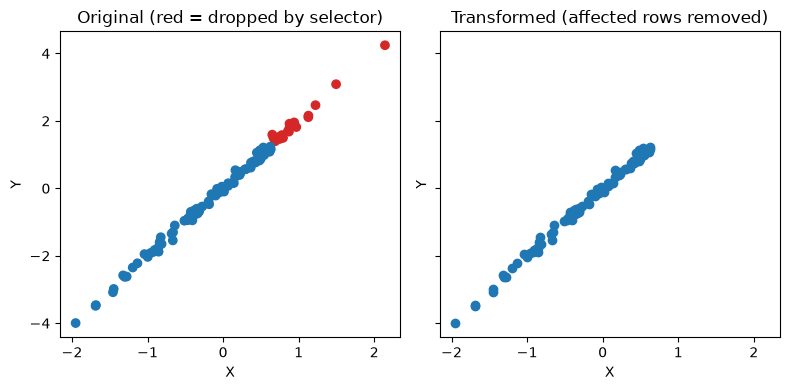

In [22]:
affected = sel(X)[0]

fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8, 4))
axes[0].scatter(X[:, 0], X[:, 1], c=np.where(affected, "C3", "C0"))
axes[1].scatter(Xt[:, 0], Xt[:, 1], c="C0")
axes[0].set_title("Original (red = dropped by selector)")
axes[1].set_title("Transformed (affected rows removed)")
axes[0].set_xlabel("X"); axes[0].set_ylabel("Y")
axes[1].set_xlabel("X"); axes[1].set_ylabel("Y")
plt.tight_layout()

## Summary

| Lever | Generator | Uses a DGP? | Effect on shape | Selection parameter |
|---|---|---|---|---|
| observation process | `RandomSamplingClassesGenerator` | no | drops affected rows | `ClassSelector` (per-class shares) |
| observation process | `RandomSamplingTargetsGenerator` | no | weighted resampling, size = input | fractional selector: `ProportionalSelector` (float scores) |
| observation process | `RandomSamplingTargetsGenerator` | no | resampling by keep-probability | boolean selector: `ClassSelector` (selected rows dropped exactly) |
| DGP | `CausalImbalanceGenerator` | **yes** (fitted) | truncates to a quantile range / drops affected rows | `quantile_range`, or explicit `selector` |
* Imbalance is a *row-removing* deficit: `Xt` is smaller than `X`.
* The selector decides **who** is affected;
  the generator realizes the decision.
* Truncation keeps rows as-is — descendants are untouched, the subset
  stays structurally consistent.


## Takeaways

- Imbalance is a row-removing deficit: the output has FEWER rows than the input.
- Selectors quantify which rows are affected; intensities (rate, quantile) are constructor arguments.
- `CausalImbalanceGenerator` needs no DGP: dropping rows never re-evaluates structural equations.